# 1. Introduction

**Latar Belakang**

Masakan Padang memiliki berbagai jenis makanan dengan tampilan yang berbeda - beda, tetapi beberapa jenis makanan memiliki warna, bentuk dan cara penyajian yang hampir mirip. Sehingga membuat orang yang belum familiar dengan Masakan Padang termasuk Wisatawan kesulitan dalam mengenali jenis Masakan Padang hanya dari gambar.

Berdasarkan permasalahan tersebut, project ini menggunakan Computer Vision untuk membuat model klasifikasi gambar yang dapat mengenali berbagai jenis Masakan Padang dari sebuah gambar.

**Dataset**

Dataset yang digunakan adalah dataset dari `Kaggle` yang bernama `Padang Cuisine (Indonesian Food Image Dataset)`. Dataset ini berisi 993 gambar yang terdiri dari 9 Jenis Masakan Padang, yaitu : `Ayam Goreng`, `Ayam Pop`, `Daging Rendang`, `Dendeng Batokok`, `Gulai Ikan`, `Gulai Tambusu`, `Gulai Tunjang`, `Telur Balado` dan `Telur Dadar`. Jadi dataset ini yang akan digunakan untuk melakukan pembuatan model.

**Link Dataset :** https://www.kaggle.com/datasets/faldoae/padangfood

**Objective yang ingin dicapai**
1. Memahami karakteristik gambar dari setiap kelas Makanan Padang.
2. Membuat model yang dapat mengidentifikasi jenis Makanan Padang dari suatu gambar.
3. Membuat Model Kedua sebagai improvement dari Model Pertama.

**Target Pengguna**

Model ini untuk pengguna yang belum familiar dengan Masakan Padang atau Wisatawan jika ingin mengetahui jenis Masakan Padang dari suatu gambar.




# 2. Import Libraries

In [1]:
import os
import matplotlib.pyplot as plt
import kagglehub
import tensorflow as tf
import pandas as pd
import random
import shutil
import numpy as np
import seaborn as sns
from keras.applications import ConvNeXtSmall
from keras.applications.convnext import preprocess_input as preprocess_input_convnext
from keras.applications.vgg16 import VGG16, preprocess_input as preprocess_input_vgg16
from tensorflow.keras.callbacks import EarlyStopping
from google.colab import userdata
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, Conv2D, MaxPooling2D, Flatten, Input
from sklearn.metrics import confusion_matrix, classification_report

# 3. Data Loading

## 3.1 Download Dataset

In [2]:
%%time
# Download Dataset
# Source dataset : https://www.kaggle.com/datasets/faldoae/padangfood

!kaggle datasets download -d faldoae/padangfood

Dataset URL: https://www.kaggle.com/datasets/faldoae/padangfood
License(s): ODbL-1.0
100% 114M/114M [00:03<00:00, 35.0MB/s]

CPU times: user 27.8 ms, sys: 4 ms, total: 31.8 ms
Wall time: 6.17 s


## 3.2 Extract Dataset

In [3]:
# Every dataset that downloaded from Kaggle is in format `.zip`. So, we must unzip it before we can using the dataset.

!unzip -qq ./padangfood.zip

## 3.3 Mengecek berapa banyak gambar di dataset

In [4]:
# Define path

main_path = '/content/dataset_padang_food'

In [5]:
# Check how many data in dataset

def check_path(path):
  total = 0
  labels = os.listdir(path)
  for label in labels:
    num_data = len(os.listdir(os.path.join(path, label)))
    total += num_data
    print(f'Total Data - {label} : {num_data}')
  print('---------------------------------------')
  print('Total Gambar :', total)

print('Main Path')
print()
check_path(main_path)

Main Path

Total Data - daging_rendang : 104
Total Data - ayam_pop : 113
Total Data - telur_balado : 111
Total Data - gulai_tunjang : 119
Total Data - telur_dadar : 116
Total Data - ayam_goreng : 107
Total Data - dendeng_batokok : 109
Total Data - gulai_ikan : 111
Total Data - gulai_tambusu : 103
---------------------------------------
Total Gambar : 993


**Analysis :**

Berdasarkan hasil analisis diatas, dapat diambil kesimpulan bahwa dataset terdiri dari `993 gambar` yang terbagi ke dalam `9 kelas Masakan Padang` yaitu `daging_rendang`, `ayam_pop`, `telur_balado`, `gulai_tunjang`, `telur_dadar`, `ayam_goreng`, `dendeng_batokok`, `gulai_ikan` dan `gulai_tambusu`. Lalu jumlah gambar pada setiap kelas itu berada di antara `103 gambar` sampai `119 gambar` yang berarti bahwa distribusi jumlah data gambar antar kelas relatif seimbang.

Lalu dataset gambar ini sudah dipisahkan berdasarkan kelas di sebuah folder, sehingga dapat langsung digunakan tanpa perlu membuat DataFrame.

# 4. Exploratory Data Analysis (EDA)

## 4.1 Memvisualisasikan 5 gambar pertama dari setiap kelas

In [6]:
# Function to visualize the first 5 images from each class

def plot_images(path):
  labels = os.listdir(path)
  for label in labels:
    folder_path = os.path.join(path, label)
    fig = plt.figure(figsize=(20, 20))
    columns = 5
    rows = 1
    print('Class : ', label)
    images = os.listdir(folder_path)
    for index in range(1, columns*rows +1):
        fig.add_subplot(rows, columns, index)
        image = plt.imread(os.path.join(folder_path, images[index]))
        plt.imshow(image)
        plt.axis("off")
    plt.show()

Class :  daging_rendang


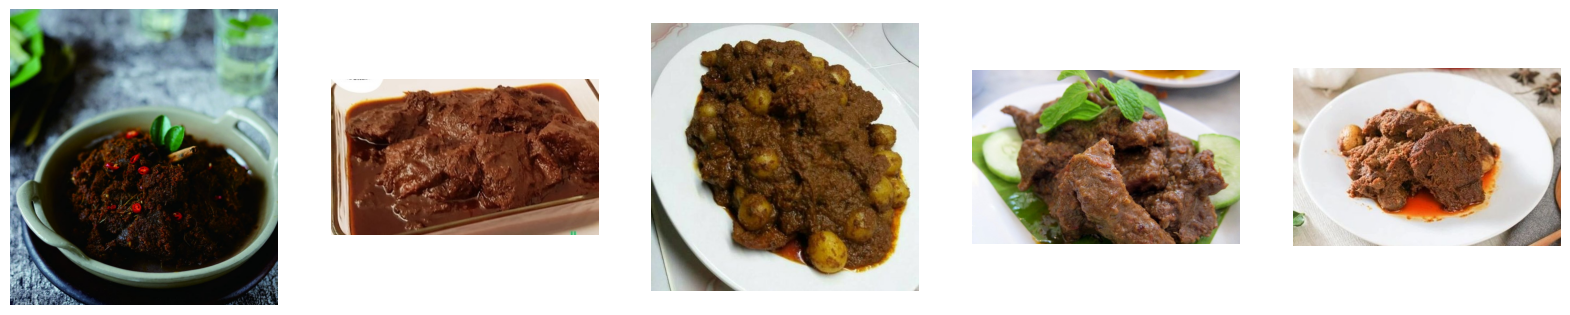

Class :  ayam_pop


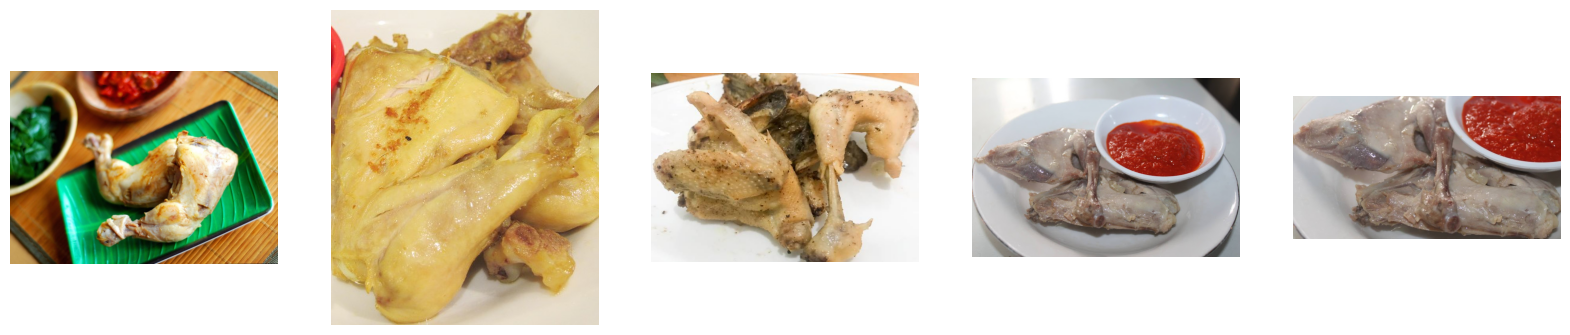

Class :  telur_balado


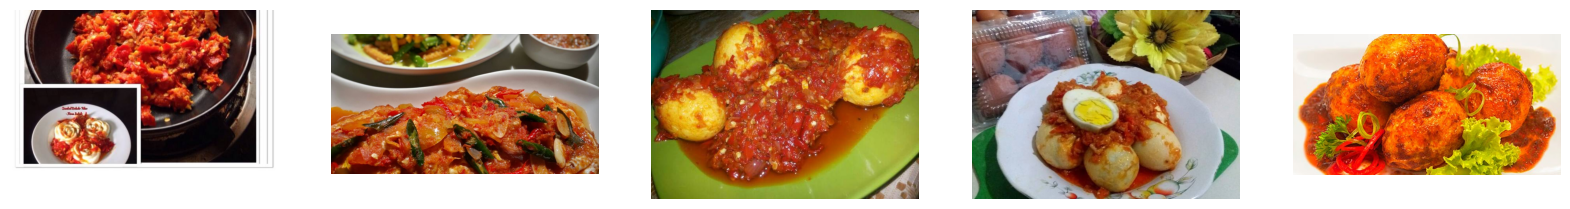

Class :  gulai_tunjang


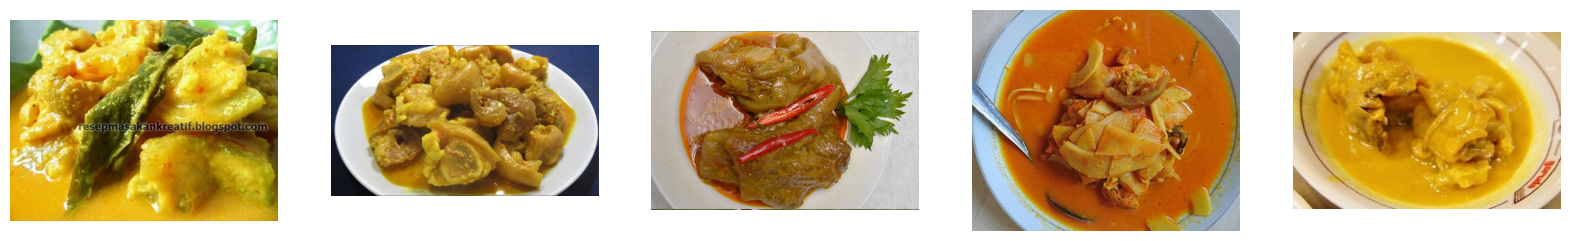

Class :  telur_dadar


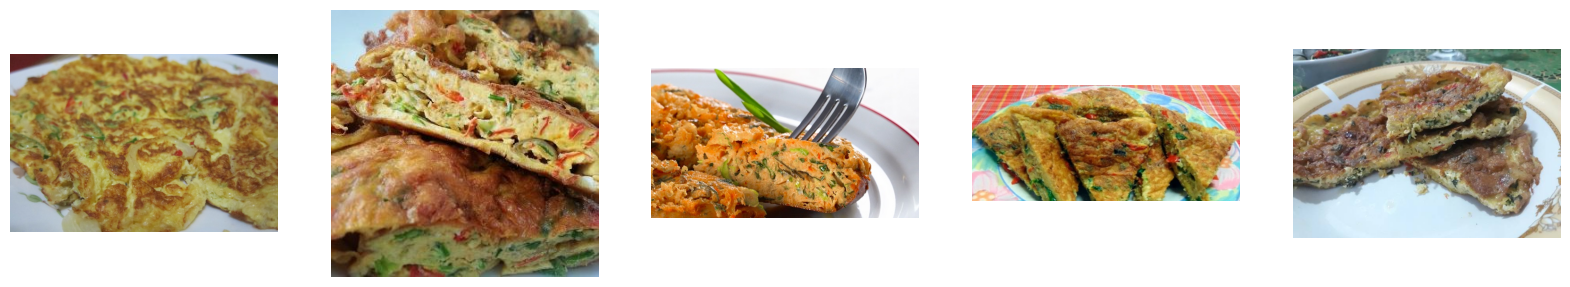

Class :  ayam_goreng


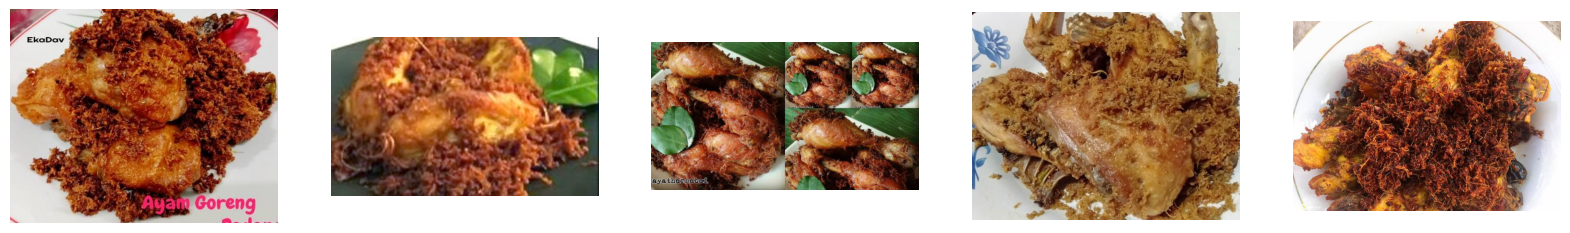

Class :  dendeng_batokok


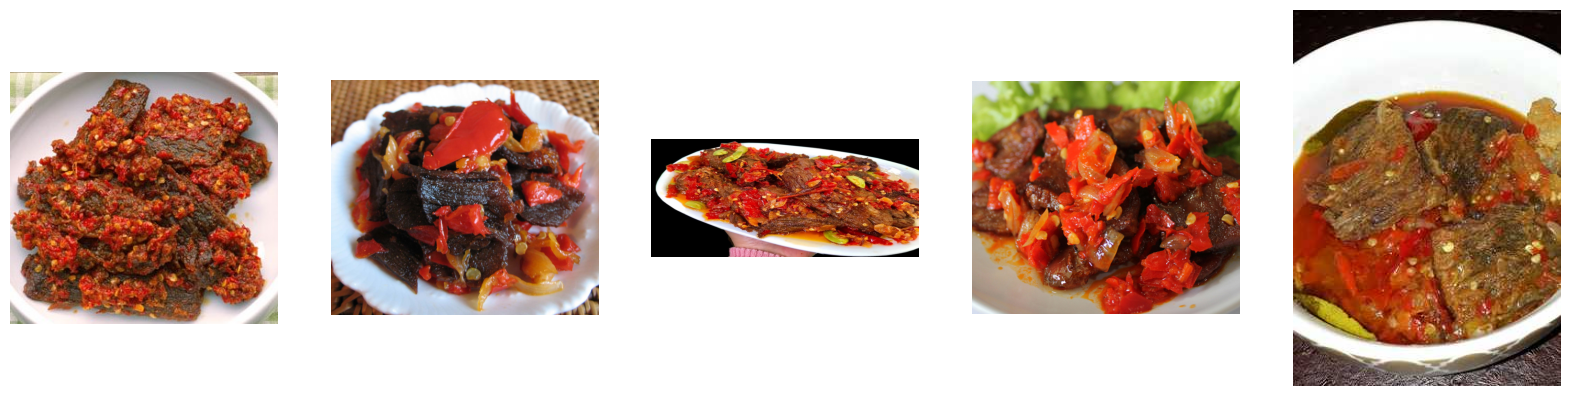

Class :  gulai_ikan


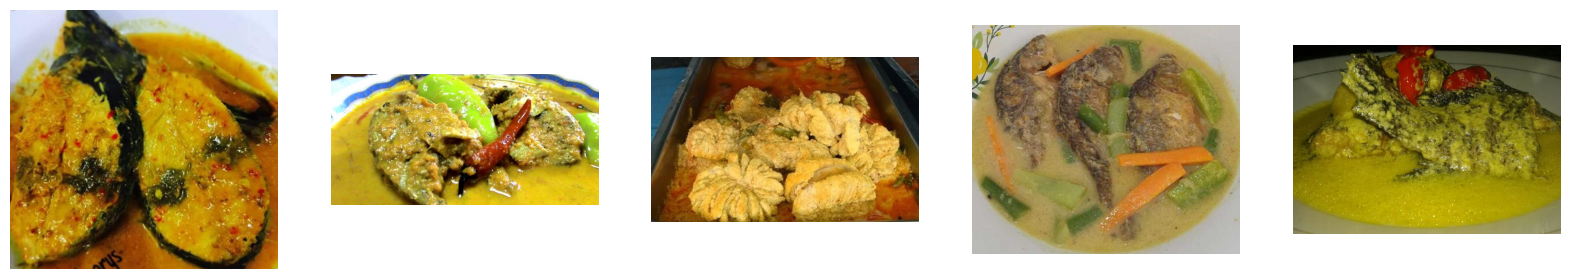

Class :  gulai_tambusu


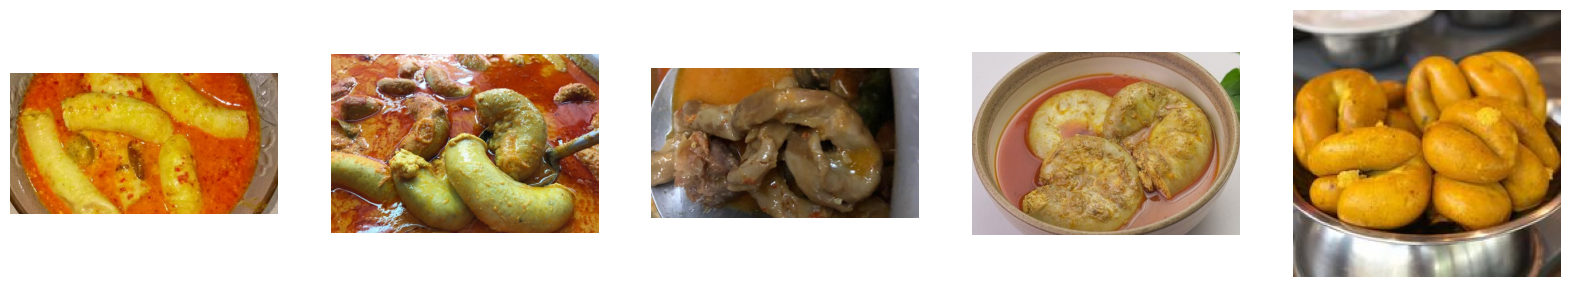

In [7]:
# Visualization of main_path

plot_images(main_path)

## 4.2 Karakteristik dari gambar

Berdasarkan hasil visualisasi sampel dari gambar diatas dapat diambil kesimpulan bahwa setiap kelas makanan itu memiliki karakteristik yang berbeda - beda, dari segi warna, tekstur, bentuk dan cara penyajiannya. Contohnya seperti : Ayam pop cenderung berwarna lebih terang, Rendang cenderung lebih gelap atau berwarna coklat dan Telur Balado lebih dominan berwarna merah.

Tapi ada beberapa kelas juga yang memiliki warna dan tekstur hampir mirip. Seperti berbagai jenis gulai contohnya Gulai Tambusu, Gulai Ikan dan Gulai Tunjang.

Tapi selain warna, tekstur, bentuk dan cara penyajiannya, perlu diperhatikan juga dari latar belakang, segi pencahayaan, jenis piring, dll. Karena hal itu juga mempengaruhi dalam memprediksi jenis Makanan Padang dari suatu gambar.

## 4.3 Angle dan Posisi Gambar

Berdasarkan hasil analisis gambar pada dataset, terlihat bahwa pengambilan gambar di setiap kelas dari dataset cukup bervariasi. Beberapa gambar diambil dari arah atas, sedangkan yang lainnya diambil dari sudut yang lebih miring.

Lalu untuk posisi gambarnya ada yang diambil dengan jarak yang dekat (close-up / zoom), ada juga gambar yang diambil dengan jarak yang lebih jauh, lalu ada juga gambar yang posisinya ditengah frame.

## 4.4 Dimension Color dan Ukuran Gambar

In [8]:
# Checking image size for each class
labels = os.listdir(main_path)
for label in labels:
  folder_path = os.path.join(main_path, label)
  images = os.listdir(folder_path)
  image = plt.imread(os.path.join(folder_path, images[0]))
  print('Class :', label)
  print('Shape :', image.shape)
  print()


Class : daging_rendang
Shape : (400, 400, 4)

Class : ayam_pop
Shape : (208, 322, 3)

Class : telur_balado
Shape : (577, 768, 3)

Class : gulai_tunjang
Shape : (720, 772, 3)

Class : telur_dadar
Shape : (482, 680, 3)

Class : ayam_goreng
Shape : (231, 352, 3)

Class : dendeng_batokok
Shape : (389, 700, 3)

Class : gulai_ikan
Shape : (532, 751, 3)

Class : gulai_tambusu
Shape : (294, 320, 3)



Berdasarkan hasil pengecekan diatas dapat diambil kesimpulan bahwa ukuran gambar untuk setiap kelas sangat beragam. Sebagai contoh untuk kelas gulai_tambusu, ukuran gambarnya adalah 630x1200 piksel dan untuk kelas gulai_ikan, ukuran gambarnya adalah 661x731 piksel dan begitupun sampai seterusnya.

Lalu untuk channel warna pada gambar di setiap kelas sama yaitu ada 3, yang berarti format gambarnya adalah RGB (Red, Green, Blue).

Dikarenakan ukuran gambar setiap kelas berbeda - beda perlu dilakukan resize agar memiliki ukuran gambar yang sama untuk setiap kelas

## 4.5 EDA Insight

Berdasarkan hasil EDA diatas, dapat disimpulkan bahwa dataset ini memiliki karakteristik gambar yang cukup beragam dari sisi warna, bentuk makanan, background, pencahayaan, sudut pengambilan gambar dan posisi objek. Beberapa kelas juga memiliki karakteristik gambar yang hampir mirip, terutama pada makanan yang menggunakan kuah atau bumbu dengan warna yang hampir sama.

Selain itu, ukuran gambar pada dataset ini tidak seragam  / tidak sama sehingga diperlukan proses resize sebelum data gambar digunakan sebagai input dari model. Variasi sudut, posisi dan jarak pengambilan gambar juga menjadi dasar penggunaan data augmentation agar model dapat belajar dari kondisi gambar yang lebih beragam.

# 5. Feature Engineering

## 5.1 Split Dataset menjadi Train, Validation dan Test Data

In [9]:
# Define output path for splitted dataset

split_path = '/content/padang_food_split/'

train_path = os.path.join(split_path, 'train')
val_path = os.path.join(split_path, 'val')
test_path = os.path.join(split_path, 'test')

In [10]:
# Set random seed
random.seed(42)

# Rasio Split Data
train_ratio = 0.70
val_ratio = 0.15
test_ratio = 0.15

try:
  # Buat folder train, validation dan test
  os.makedirs(train_path)
  os.makedirs(val_path)
  os.makedirs(test_path)

  labels = os.listdir(main_path)

  for label in labels:
      class_path = os.path.join(main_path, label)
      images = os.listdir(class_path)
      random.shuffle(images)
      total_images = len(images)

      train_size = int(total_images * train_ratio)
      val_size = int(total_images * val_ratio)

      # Split nama file
      train_images = images[:train_size]

      val_images = images[train_size:train_size + val_size]

      test_images = images[train_size + val_size:]

      # Buat folder antar class
      os.makedirs(os.path.join(train_path, label))
      os.makedirs(os.path.join(val_path, label))
      os.makedirs(os.path.join(test_path, label))

      # Copy gambar training
      for image in train_images:
          shutil.copy2(
              os.path.join(class_path, image),
              os.path.join(train_path, label, image)
          )

      # Copy gambar validation
      for image in val_images:
          shutil.copy2(
              os.path.join(class_path, image),
              os.path.join(val_path, label, image)
          )

      # Copy gambar testing
      for image in test_images:
          shutil.copy2(
              os.path.join(class_path, image),
              os.path.join(test_path, label, image)
          )

except FileExistsError:
  print('folder alreaddy exist')

In [11]:
# Check jumlah gambar setelah di split

print('Train Path')
check_path(train_path)

print('\nValidation Path')
check_path(val_path)

print('\nTest Path')
check_path(test_path)

Train Path
Total Data - daging_rendang : 72
Total Data - ayam_pop : 79
Total Data - telur_balado : 77
Total Data - gulai_tunjang : 83
Total Data - telur_dadar : 81
Total Data - ayam_goreng : 74
Total Data - dendeng_batokok : 76
Total Data - gulai_ikan : 77
Total Data - gulai_tambusu : 72
---------------------------------------
Total Gambar : 691

Validation Path
Total Data - daging_rendang : 15
Total Data - ayam_pop : 16
Total Data - telur_balado : 16
Total Data - gulai_tunjang : 17
Total Data - telur_dadar : 17
Total Data - ayam_goreng : 16
Total Data - dendeng_batokok : 16
Total Data - gulai_ikan : 16
Total Data - gulai_tambusu : 15
---------------------------------------
Total Gambar : 144

Test Path
Total Data - daging_rendang : 17
Total Data - ayam_pop : 18
Total Data - telur_balado : 18
Total Data - gulai_tunjang : 19
Total Data - telur_dadar : 18
Total Data - ayam_goreng : 17
Total Data - dendeng_batokok : 17
Total Data - gulai_ikan : 18
Total Data - gulai_tambusu : 16
---------

In [12]:
# Menghitung total gambar
def count_total_images(path):
    total = 0

    for label in os.listdir(path):
        total += len(os.listdir(os.path.join(path, label)))
    return total

print('Total Data Train      :', count_total_images(train_path))
print('Total Data Validation :', count_total_images(val_path))
print('Total Data Test       :', count_total_images(test_path))
print('Total Data Keseluruhan :', (count_total_images(train_path) + count_total_images(val_path) + count_total_images(test_path)))

Total Data Train      : 691
Total Data Validation : 144
Total Data Test       : 158
Total Data Keseluruhan : 993


**Analysis :**

Dataset akan dibagi menjadi 3 bagian dengan proporsi 70% data training, 15% data validation dan 15% data testing.

- Training set (70%) digunakan untuk melatih model.
- Validation set (15%) digunakan untuk mengecek performa model selama proses training.
- Test set (15%) digunakan untuk mengevaluasi performa akhir model pada data yang tidak pernah digunakan selama proses training.

Alasan memakai proporsi ratio pembagian 70:15:15 dikarenakan ratio ini adalah ratio pembagian standar yang cocok untuk dataset kecil hingga menengah (Ratusan hingga Puluhan Ribu Gambar). Total Dataset Makanan Padang adalah 993 gambar, sehingga cocok menggunakan ratio ini.

Pembagian dilakukan pada setiap kelas dengan `random.seed(42)` agar proses pembagian data dapat direproduksi. Lalu pembagian per kelas juga membantu mempertahankan representasi dari seluruh kelas makanan pada train, validation, dan test set.

Setelah dilakukan split data ditemukan hasil bahwa terdapat total data training adalah 691 gambar, total data validation adalah 144 gambar dan total data test adalah 158 gambar dengan total keseluruhan data tetap sebanyak 993 gambar.

## 5.2 Resize Gambar

In [13]:
# Define hyperparameters

img_height= 224
img_width= 224
batch_size= 64

**Analysis :**

Berdasarkan hasil EDA sebelumnya terlihat bahwa ukuran gambar setiap kelas itu berbeda - beda. Sehingga perlu diseragamkan menjadi 1 ukuran agar dapat digunakan sebagai input model.

Pada penelitian ini ukuran gambar yang ditetapkan untuk seluruh gambar makanan pada dataset adalah 224x224 piksel. Alasan dipilihnya ukuran 224x224 piksel adalah karena ukuran ini bisa tetap mempertahankan informasi visual dari objek makanan sekaligus menjaga kebutuhan komputasi agar tidak terlalu besar. Selain itu ukuran 224x224 piksel ini juga cocok untuk ukuran input yang umum digunakan pada model seperti VGG16 yang nantinya akan digunakan di tahap ANN Improvement.

Selain ukuran gambar digunakan batch_size = 64 juga karena ukuran ini sering digunakan untuk memberikan keseimbangan yang optimal antara kecepatan komputasi dan efisiensi memori (CPU / GPU).

### 5.3 Data Augmentation

In [14]:
# Create batch generator for train-set, val-set, and test-set

train_datagen_aug = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255.,
                                                                    rotation_range=20,
                                                                    zoom_range=0.05,
                                                                    width_shift_range=0.05,
                                                                    height_shift_range=0.05,
                                                                    shear_range=0.05,
                                                                    horizontal_flip=True)

val_datagen_aug = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255.)
test_datagen_aug = tf.keras.preprocessing.image.ImageDataGenerator(rescale=1./255.)

train_set_aug = train_datagen_aug.flow_from_directory(train_path,
                                                      target_size=(img_height,img_width),
                                                      class_mode='sparse',
                                                      batch_size=batch_size,
                                                      shuffle=True,
                                                      seed=2)

val_set_aug = val_datagen_aug.flow_from_directory(val_path,
                                                    target_size=(img_height,img_width),
                                                    class_mode='sparse',
                                                    batch_size=batch_size,
                                                    shuffle=False,
                                                    seed=2)

test_set_aug = test_datagen_aug.flow_from_directory(test_path,
                                                    target_size=(img_height,img_width),
                                                    class_mode='sparse',
                                                    batch_size=batch_size,
                                                    shuffle=False,
                                                    seed=2)

Found 691 images belonging to 9 classes.
Found 144 images belonging to 9 classes.
Found 158 images belonging to 9 classes.


**Analysis :**

Dilakukan Data Augmentation pada data training untuk menambah variasi gambar tanpa perlu menambah data baru secara manual. Hal ini dilakukan agar model tidak terlalu bergantung pada posisi, sudut atau pengambilan foto dari gambar training. Sehingga diharapkan kemampuan modelnya akan jauh lebih baik dalam memprediksi gambar.

Augmentasi yang dilakukan adalah :
- `rotation_range = 20` untuk memberikan variasi rotasi gambar hingga 20 derajat.
- `zoom_range = 0.05` untuk memberikan variasi zoom pada gambar.
- `width_shift_range = 0.05` dan `height_shift_range = 0.05` untuk menggeser posisi gambar menjadi vertikal ataupun horizontal.
- `shear_range = 0.05` untuk memberikan sedikit perubahan perspektif pada gambar.
- `horizontal_flip = True` untuk membalik gambar secara horizontal.

Augmentasi ini hanya dilakukan di Data Training dan tidak diterapkan di Data Validation dan Test. Karena Data Validation dan Data Test digunakan untuk menguji model ketika diberi gambar aslinya.

# 6. ANN Training (Sequential API / Functional API)

## 6.1 Model Definition

In [15]:
# Clear session

seed = 20
tf.keras.backend.clear_session()
np.random.seed(seed)
tf.random.set_seed(seed)

In [16]:
# Create Sequential API model

model_aug = Sequential()
model_aug.add(Conv2D(32, (3,3), activation='relu', input_shape=(img_height, img_width,3)))
model_aug.add(MaxPooling2D(2, 2))
model_aug.add(Conv2D(64, (3,3), activation='relu'))
model_aug.add(MaxPooling2D(2, 2))
model_aug.add(Conv2D(128, (3,3),activation='relu'))
model_aug.add(MaxPooling2D(2, 2))
model_aug.add(Flatten())
model_aug.add(Dropout(0.5))
model_aug.add(Dense(512, activation='relu'))
model_aug.add(Dense(9, activation='softmax'))

# Compile
model_aug.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])
model_aug.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         4,617 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,400,713 (169.38 MB)

 Trainable params: 44,400,713 (169.38 MB)

 Non-trainable params: 0 (0.00 B)

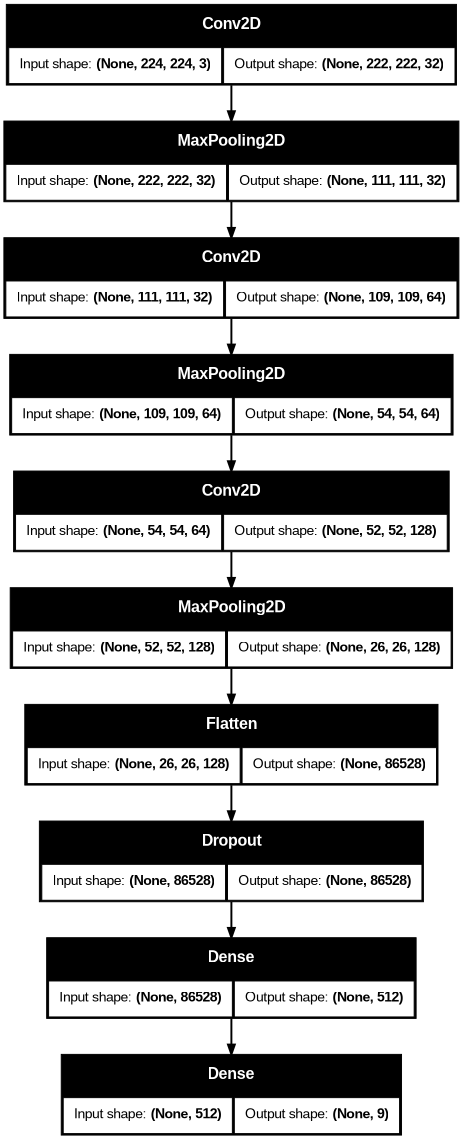

In [17]:
# Plot layers

tf.keras.utils.plot_model(model_aug, show_shapes=True, dpi=70)

**Analysis :**

Model pertama menggunakan Convolutional Neural Network (CNN) sebagai baseline. Alasan menggunakan CNN adalah karena CNN mampu mempelajari pola visual dari suatu gambar, seperti warna, bentuk gambar, dll. Output layer menggunakan 9 neuron dengan aktivasi softmax karena terdapat 9 kelas makanan.

## 6.2 Model Training

In [18]:
# Train the model

%%time
history_aug = model_aug.fit(train_set_aug, epochs=30, validation_data=val_set_aug, batch_size=batch_size)

Epoch 1/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.1563 - loss: 3.6913 - val_accuracy: 0.2917 - val_loss: 2.0430
Epoch 2/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.2735 - loss: 1.8887 - val_accuracy: 0.2778 - val_loss: 1.7915
Epoch 3/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.3792 - loss: 1.6621 - val_accuracy: 0.4097 - val_loss: 1.4639
Epoch 4/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.4443 - loss: 1.3854 - val_accuracy: 0.4653 - val_loss: 1.3169
Epoch 5/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.5485 - loss: 1.2221 - val_accuracy: 0.4931 - val_loss: 1.4484
Epoch 6/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.5485 - loss: 1.2101 - val_accuracy: 0.5347 - val_loss: 1.2215
Epoch 7/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.5731 - loss: 1.1815 - val_accuracy: 0.5694 - val_loss: 1.1404
Epoch 8/30
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.5933 - loss: 1.0644 - val_accuracy: 0.6042 - val_loss:

**Analysis :**

Model dilatih menggunakan data training yang telah di augmentasi dan di rescaling. Proses training dilakukan selama 30 epoch dengan validation set untuk menguji performa model pada data yang tidak digunakan langsung ketika proses training / proses pembelajaran.

## 6.3 Model Evaluation

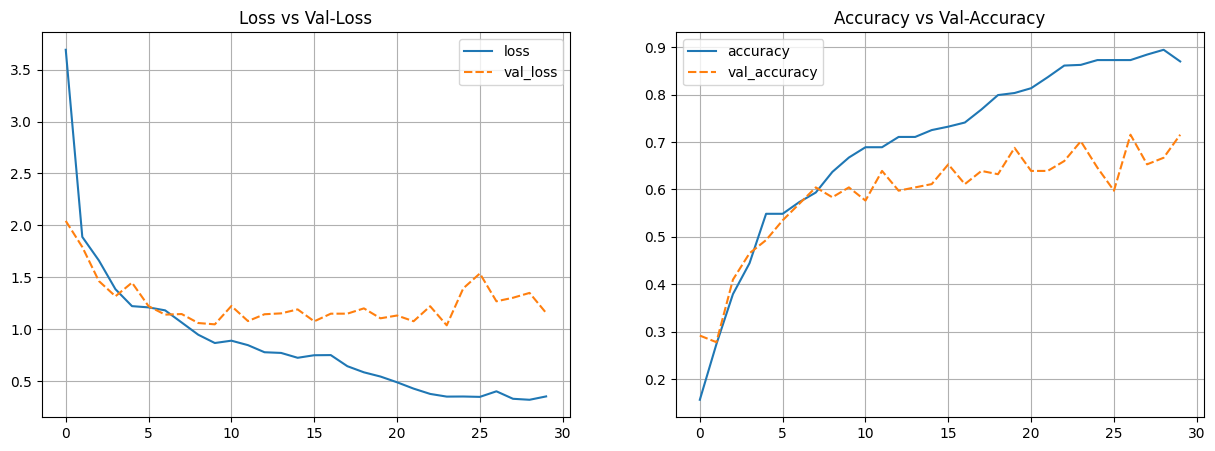

In [19]:
# Plot training results

history_aug_df = pd.DataFrame(history_aug.history)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.lineplot(data=history_aug_df[['loss', 'val_loss']])
plt.grid()
plt.title('Loss vs Val-Loss')

plt.subplot(1, 2, 2)
sns.lineplot(data=history_aug_df[['accuracy', 'val_accuracy']])
plt.grid()
plt.title('Accuracy vs Val-Accuracy')
plt.show()

In [20]:
# Check the performance of test-set

## Get the probability
y_pred_prob_aug = model_aug.predict(test_set_aug)

## Get class with maximum probability
y_pred_class_aug = np.argmax(y_pred_prob_aug, axis=-1)

## Display Classification Report
print(classification_report(test_set_aug.classes, y_pred_class_aug, target_names=np.array(list(train_set_aug.class_indices.keys()))))

3/3 ━━━━━━━━━━━━━━━━━━━━ 3s 793ms/step
                 precision    recall  f1-score   support

    ayam_goreng       0.54      0.82      0.65        17
       ayam_pop       0.69      1.00      0.82        18
 daging_rendang       0.93      0.82      0.88        17
dendeng_batokok       0.94      0.94      0.94        17
     gulai_ikan       0.50      0.72      0.59        18
  gulai_tambusu       0.75      0.19      0.30        16
  gulai_tunjang       0.62      0.53      0.57        19
   telur_balado       0.67      0.67      0.67        18
    telur_dadar       0.70      0.39      0.50        18

       accuracy                           0.68       158
      macro avg       0.71      0.68      0.66       158
   weighted avg       0.70      0.68      0.66       158



**Analysis :**

Berdasarkan hasil grafik training diatas dapat terlihat bahwa model CNN ini memiliki kecenderungan `overfitting`. Lalu pada epoch terakhir akurasi trainingnya mencapai sekitar `86,98%`, sedangkan untuk akurasi dari validationnya berada di sekitar `71,53%`. Lalu training loss nya menurun hingga sekitar `0,35` dan validation lossnya masih berada di sekitar `1,15`. Hal ini berarti bahwa model semakin baik dalam mempelajari data training, tapi performanya pada data validation tidak meningkat.

Lalu pada data test, model memiliki akurasi sebesar 68% dengan macro average F1-Score sebesar 0,66. Berdasarkan hasil analisis diatas kelas yang paling baik dikenali adalah kelas `dendeng_batokok` dengan F1-Score sebesar `0,94`, lalu kelas kedua yang paling baik dikenali adalah kelas `daging rendang` dengan F1-Score sebesar `0,88` lalu diikuti dengan kelas `ayam_pop` sebesar `0,82`.

Lalu kelas yang paling sulit dikenali adalah kelas `gulai_tambusu` karena hanya memiliki F1-Score sebesar `0,30`. Hal ini berarti bahwa performa CNN baseline masih belum optimal dan masih terdapat beberapa kelas makanan yang sulit dibedakan. Sehingga diperlukan ANN Improvemnt untuk meningkatkan performa model.

# 7. ANN Improvement (Sequential API / Functional API)

# 7.1 VGG16

### 7.1.1 Model Definition

In [21]:
# Define hyperparameters

img_height= 224
img_width= 224
batch_size= 64

In [22]:
# Download pretrained model

pretrained_model_vgg16 = VGG16(weights='imagenet', include_top=False, input_shape=(img_height,img_width, 3))
pretrained_model_vgg16.trainable = False

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [23]:
# Create batch generator for train-set, val-set, and test-set

train_datagen_t1_vgg16 = tf.keras.preprocessing.image.ImageDataGenerator(rotation_range=20,
                                                                    zoom_range=0.05,
                                                                    width_shift_range=0.05,
                                                                    height_shift_range=0.05,
                                                                    shear_range=0.05,
                                                                    horizontal_flip=True,
                                                                    preprocessing_function=preprocess_input_vgg16)

val_datagen_t1_vgg16 = tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=preprocess_input_vgg16)
test_datagen_t1_vgg16 = tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=preprocess_input_vgg16)

train_set_tl_vgg16 = train_datagen_t1_vgg16.flow_from_directory(train_path,
                                                      target_size=(img_height,img_width),
                                                      class_mode='sparse',
                                                      batch_size=batch_size,
                                                      shuffle=True,
                                                      seed=2)

val_set_tl_vgg16 = val_datagen_t1_vgg16.flow_from_directory(val_path,
                                                    target_size=(img_height,img_width),
                                                    class_mode='sparse',
                                                    batch_size=batch_size,
                                                    shuffle=False,
                                                    seed=2)

test_set_tl_vgg16 = test_datagen_t1_vgg16.flow_from_directory(test_path,
                                                  target_size=(img_height,img_width),
                                                  class_mode='sparse',
                                                  batch_size=batch_size,
                                                  shuffle=False,
                                                  seed=2)

Found 691 images belonging to 9 classes.
Found 144 images belonging to 9 classes.
Found 158 images belonging to 9 classes.


In [24]:
# Clear session

seed = 20
tf.keras.backend.clear_session()
np.random.seed(seed)
tf.random.set_seed(seed)

In [25]:
# Create Sequential API model

model_tl_vgg16 = Sequential()
model_tl_vgg16.add(pretrained_model_vgg16)
model_tl_vgg16.add(Flatten())
model_tl_vgg16.add(Dense(128, activation='relu'))
model_tl_vgg16.add(Dense(9, activation='softmax'))

# Compile
model_tl_vgg16.compile(loss='sparse_categorical_crossentropy',
                       optimizer='adam',
                       metrics=['accuracy'])
model_tl_vgg16.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 17,927,241 (68.39 MB)

 Trainable params: 3,212,553 (12.25 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

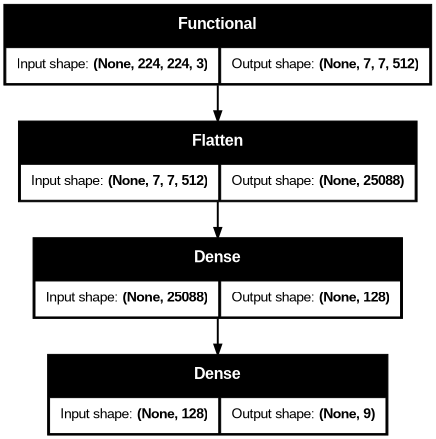

In [26]:
# Plot layers

tf.keras.utils.plot_model(model_tl_vgg16, show_shapes=True, dpi=70)

**Analysis :**

Model VGG16 memiliki sekitar 17,9 juta parameter, akan tetapi hanya sekitar 3,2 juta parameter yang dilatih, karena layer pretained VGG16 dibekukan. Sehingga hal ini dapat membuat model memanfaatkan fitur visual yang sudah dipelajari sebelumnya tanpa melatih seluruh jaringan dari awal.

### 7.1.2 Model Training

In [27]:
# Define EarlyStopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

In [28]:
# Train the model

%%time
history_tl_vgg16 = model_tl_vgg16.fit(train_set_tl_vgg16, epochs=1000, validation_data=val_set_tl_vgg16, callbacks = [early_stopping], batch_size=batch_size)

Epoch 1/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 31s 2s/step - accuracy: 0.4182 - loss: 37.2838 - val_accuracy: 0.5833 - val_loss: 8.7043
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.7511 - loss: 2.9379 - val_accuracy: 0.7083 - val_loss: 4.3290
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.8596 - loss: 1.3481 - val_accuracy: 0.7153 - val_loss: 3.2882
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9103 - loss: 0.4891 - val_accuracy: 0.7083 - val_loss: 3.1185
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9190 - loss: 0.5023 - val_accuracy: 0.7222 - val_loss: 3.2275
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.9508 - loss: 0.3634 - val_accuracy: 0.7639 - val_loss: 2.7875
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.9363 - loss: 0.2901 - val_accuracy: 0.7778 - val_loss: 3.0770
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9667 - loss: 0.2444 - val_accuracy: 0

**Analysis :**

Model VGG16 diberikan maksimal 1.000 epoch, tetapi digunakan EarlyStopping agar dapat menghentikan proses training ketika val_loss tidak lagi membaik selama 10 epoch.

Proses training ini berhenti pada epoch ke-18 yang memiliki validation loss terbaik. Sehingga dengan cara ini, proses trainining tidak perlu berjalan sampai 1.000 epoch dan resiko overfitting dapat dikurangi.



### 7.1.3 Model Evaluation

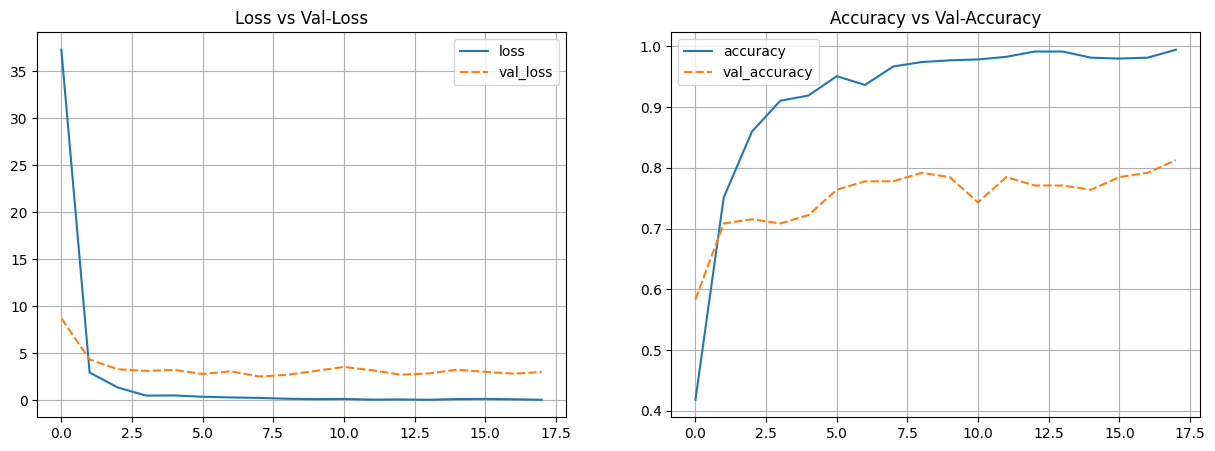

In [29]:
# Plot training results

history_tl_vgg16_df = pd.DataFrame(history_tl_vgg16.history)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.lineplot(data=history_tl_vgg16_df[['loss', 'val_loss']])
plt.grid()
plt.title('Loss vs Val-Loss')

plt.subplot(1, 2, 2)
sns.lineplot(data=history_tl_vgg16_df[['accuracy', 'val_accuracy']])
plt.grid()
plt.title('Accuracy vs Val-Accuracy')
plt.show()

In [30]:
# Check the performance of test-set

## Get the probability
y_pred_prob_tl_vgg16 = model_tl_vgg16.predict(test_set_tl_vgg16)

## Get class with maximum probability
y_pred_class_tl_vgg16 = np.argmax(y_pred_prob_tl_vgg16, axis=-1)

## Display Classification Report
print(classification_report(test_set_tl_vgg16.classes, y_pred_class_tl_vgg16, target_names=np.array(list(train_set_tl_vgg16.class_indices.keys()))))

3/3 ━━━━━━━━━━━━━━━━━━━━ 6s 2s/step
                 precision    recall  f1-score   support

    ayam_goreng       0.71      0.88      0.79        17
       ayam_pop       1.00      0.83      0.91        18
 daging_rendang       0.93      0.76      0.84        17
dendeng_batokok       1.00      0.94      0.97        17
     gulai_ikan       0.80      0.89      0.84        18
  gulai_tambusu       0.92      0.75      0.83        16
  gulai_tunjang       0.76      0.84      0.80        19
   telur_balado       0.94      0.94      0.94        18
    telur_dadar       0.90      1.00      0.95        18

       accuracy                           0.87       158
      macro avg       0.89      0.87      0.87       158
   weighted avg       0.88      0.87      0.87       158



**Analysis :**

Berdasarkan hasil evaluasi diatas terlihat bahwa VGG16 menghasilkan akurasi sebesar 87% dengan macro average F1-Score sebesar 0,87. Hasil ini meningkat cukup jauh dibandingkan CNN Baseline yang sebelumnya memperoleh akurasi sebesar 68%.

VGG16 ini mengenali sebagian besar kelas dengan cukup baik. Kelas makanan yang memiliki performa paling tinggi adalah `dendeng_batokok` dengan F1-Score sebesar `0,97`, sedangkan F1-Score terendah masih sama yaitu kelas `ayam_goreng` sebesar `0,79`.

Walaupun terdapat jarak antara performa training dan validation yang menunjukkan kecenderungan overfitting, akan tetapi penggunaan EarlyStopping dapat membantu menghentikan training sebelum model semakin overfit. Sehingga secara keseluruhan dapat disimpulkan bahwa VGG16 dapat mengenali gambar Masakan Padang yang lebih baik dibandingkan model baseline.


## 7.2 ConvNeXt

### 7.2.1 Model Definition

In [31]:
# Download pretrained model
pretrained_model_convnext = ConvNeXtSmall(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))
pretrained_model_convnext.trainable = False

198551472/198551472 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


In [32]:
# Create batch generator for train-set, val-set, and test-set

train_datagen_tl_convnext = tf.keras.preprocessing.image.ImageDataGenerator(rotation_range=20,
                                                                   zoom_range=0.05,
                                                                   width_shift_range=0.05,
                                                                   height_shift_range=0.05,
                                                                   shear_range=0.05,
                                                                   horizontal_flip=True,
                                                                   preprocessing_function=preprocess_input_convnext)

val_datagen_t1_convnext = tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=preprocess_input_convnext)
test_datagen_t1_convnext = tf.keras.preprocessing.image.ImageDataGenerator(preprocessing_function=preprocess_input_convnext)

train_set_tl_convnext = train_datagen_tl_convnext.flow_from_directory(train_path,
                                                    target_size=(img_height,img_width),
                                                    class_mode='sparse',
                                                    batch_size=batch_size,
                                                    shuffle=True,
                                                    seed=2)

val_set_tl_convnext = val_datagen_t1_convnext.flow_from_directory(val_path,
                                                  target_size=(img_height,img_width),
                                                  class_mode='sparse',
                                                  batch_size=batch_size,
                                                  shuffle=True,
                                                  seed=2)

test_set_tl_convnext = test_datagen_t1_convnext.flow_from_directory(test_path,
                                                  target_size=(img_height,img_width),
                                                  class_mode='sparse',
                                                  batch_size=batch_size,
                                                  shuffle=False,
                                                  seed=2)

Found 691 images belonging to 9 classes.
Found 144 images belonging to 9 classes.
Found 158 images belonging to 9 classes.


In [33]:
# Clear session

seed = 20
tf.keras.backend.clear_session()
np.random.seed(seed)
tf.random.set_seed(seed)

In [34]:
# Create Sequential API model

model_tl_convnext = Sequential()
model_tl_convnext.add(pretrained_model_convnext)
model_tl_convnext.add(Flatten())
model_tl_convnext.add(Dense(128, activation='relu'))
model_tl_convnext.add(Dense(9, activation='softmax'))

# Compile
model_tl_convnext.compile(loss='sparse_categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])
model_tl_convnext.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ convnext_small (Functional)     │ (None, 7, 7, 768)      │    49,454,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 37632)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,817,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │         1,161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,272,873 (207.03 MB)

 Trainable params: 4,818,185 (18.38 MB)

 Non-trainable params: 49,454,688 (188.65 MB)

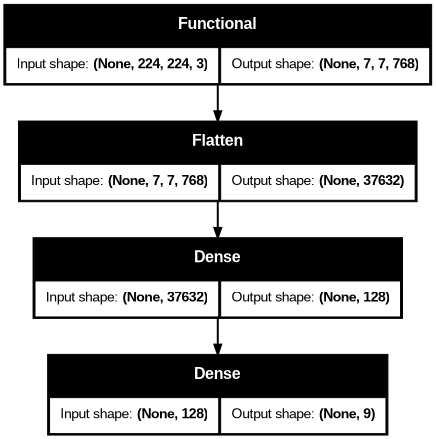

In [35]:
# Plot layers

tf.keras.utils.plot_model(model_tl_convnext, show_shapes=True, dpi=70)

**Analysis :**

ConvNext memiliki sekitar 54,27 juta parameter dengan sekitar 4,81 juta parameter yang dilatih. Jumlah parameter dan ukuran model ini jauh lebih besar dibandingkan VGG16, sehingga kebutuhan penyimpanan dan komputasinya juga lebih tinggi.

### 7.2.2 Model Training

In [36]:
# Train the model

%%time
history_tl_convnext = model_tl_convnext.fit(train_set_tl_convnext, epochs=1000, validation_data=val_set_tl_convnext, callbacks = [early_stopping], batch_size=batch_size)

Epoch 1/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 73s 4s/step - accuracy: 0.4906 - loss: 3.0608 - val_accuracy: 0.7569 - val_loss: 0.7251
Epoch 2/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.8017 - loss: 0.5657 - val_accuracy: 0.8333 - val_loss: 0.5937
Epoch 3/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9074 - loss: 0.3009 - val_accuracy: 0.8750 - val_loss: 0.4626
Epoch 4/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9493 - loss: 0.1579 - val_accuracy: 0.8958 - val_loss: 0.4769
Epoch 5/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9740 - loss: 0.0896 - val_accuracy: 0.8889 - val_loss: 0.4791
Epoch 6/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9826 - loss: 0.0408 - val_accuracy: 0.8958 - val_loss: 0.5048
Epoch 7/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.9899 - loss: 0.0400 - val_accuracy: 0.9097 - val_loss: 0.5012
Epoch 8/1000
11/11 ━━━━━━━━━━━━━━━━━━━━ 16s 1s/step - accuracy: 0.9942 - loss: 0.0281 - val_accuracy: 0.

**Analysis :**

Training ConvNeXt juga menggunakan EarlyStop dengan memonitor `val_loss`. Lalu training ConvNeXt ini berhenti pada epoch ke-13 sebagai epoch dengan validation loss terbaik.

### 7.2.3 Model Evaluation

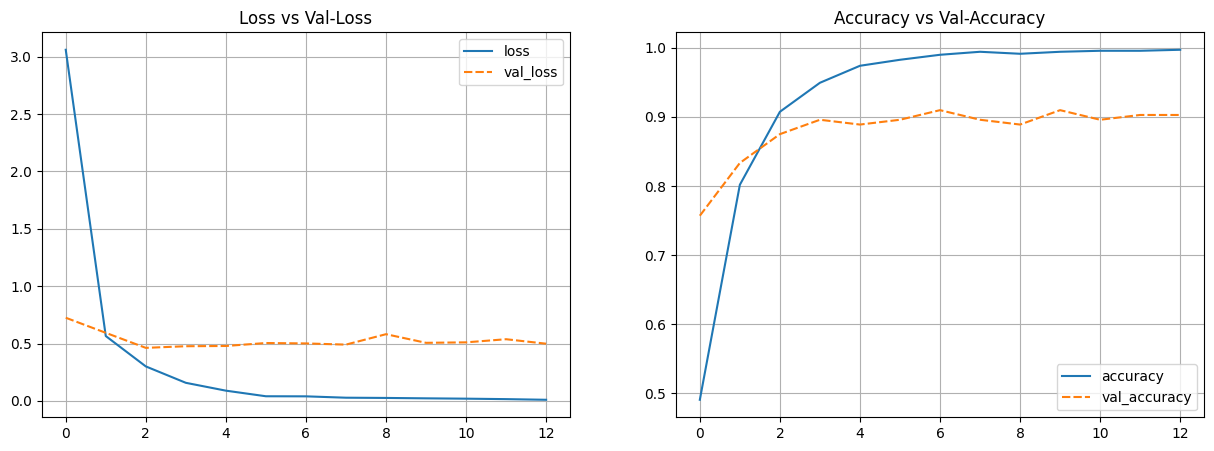

In [37]:
# Plot training results

history_tl_convnext_df = pd.DataFrame(history_tl_convnext.history)

plt.figure(figsize=(15, 5))
plt.subplot(1, 2, 1)
sns.lineplot(data=history_tl_convnext_df[['loss', 'val_loss']])
plt.grid()
plt.title('Loss vs Val-Loss')

plt.subplot(1, 2, 2)
sns.lineplot(data=history_tl_convnext_df[['accuracy', 'val_accuracy']])
plt.grid()
plt.title('Accuracy vs Val-Accuracy')
plt.show()

In [38]:
# Check the performance of test-set

## Get the probability
y_pred_prob_tl_convnext = model_tl_convnext.predict(test_set_tl_convnext)

## Get class with maximum probability
y_pred_class_tl_convnext = np.argmax(y_pred_prob_tl_convnext, axis=-1)

## Display Classification Report
print(classification_report(test_set_tl_convnext.classes, y_pred_class_tl_convnext, target_names=np.array(list(train_set_tl_convnext.class_indices.keys()))))

2/3 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 20s 6s/step
                 precision    recall  f1-score   support

    ayam_goreng       0.88      0.82      0.85        17
       ayam_pop       0.84      0.89      0.86        18
 daging_rendang       0.93      0.82      0.88        17
dendeng_batokok       0.80      0.94      0.86        17
     gulai_ikan       0.78      0.39      0.52        18
  gulai_tambusu       0.72      0.81      0.76        16
  gulai_tunjang       0.68      0.79      0.73        19
   telur_balado       0.94      0.89      0.91        18
    telur_dadar       0.82      1.00      0.90        18

       accuracy                           0.82       158
      macro avg       0.82      0.82      0.81       158
   weighted avg       0.82      0.82      0.81       158



**Analysis :**

Pada hasil analisis diatas didapatkan hasil bahwa ConvNeXt menghasilkan akurasi sebesar 82% dengan macro average F1-Score sebesar 0,81. Hasil ini sudah lebih baik dibandingkan CNN baseline, akan tetapi model ConvNeXt ini masih berada dibawah performa VGG16.

Sebagian besar kelas makanan dapat dikenali dengan cukup baik, akan tetapi model ini masih mengalami kesulitan dalam mengenali kelas `gulai_ikan`, hal ini dilihat dari hasil recall untuk kelas ini adalah `0,39` dan F1-Scorenya hanya sebesar `0,52`.

## 7.3 Model Comparison

Berdasarkan hasil analisis perbandingan antara kedua model Transfer Learning VGG16 dan ConvNeXt didapatkan hasil bahwa kedua model tersebut berhasil meningkatkan performa dibandingkan CNN Baseline. VGG16 memiliki hasil yang lebih bagus dibandingkan ConvNeXt. VGG16 menghasilkan akurasi `87%` dan macro F1-Score `0,87`. Sedangkan ConvNext hanya menghasilkan akurasi sebesar `82%`.

Selain memiliki performa tertinggi, ukuran VGG16 juga lebih kecil dibandingkan ConvNeXt. Sehingga oleh karena itu VGG16 dipilih sebagai model terbaik untuk digunakan pada tahap Model Saving, Model Inference dan Deployment.

# 8. Model Saving

In [39]:
# Save the best model
model_tl_vgg16.save('best_model_vgg16.keras')

print('Berhasil menyimpan model terbaik VGG16')

Berhasil menyimpan model terbaik VGG16


# 9. Pengambilan Kesimpulan

Berdasarkan proses yang telah dilakukan, model berhasil dibuat untuk mengklasifikasikan 9 jenis Masakan Padang menggunakan pendekatan CNN dan Transfer Learning.

Model CNN Baseline menghasilkan akurasi sebesar 68% lalu kemudian performanya meningkat setelah dilakukan improvement menggunakan Transfer Learning. Model ConvNeXt menghasilkan akurasi 82%, sedangkan VGG16 memberikan hasil terbaik dengan akurasi 87% dan macro F1-Score 0,87.

Dari hasil tersebut membuat VGG16 dipilih sebagai model terbaik karena memiliki performa paling tinggi dan hasil klasifikasi yang lebih konsisten dibandingkan model lainnya. Model ini kemudian disimpan untuk digunakan pada tahap inference dan deployment.

Secara keseluruhan, penggunaan transfer learning terbukti mampu meningkatkan performa klasifikasi dibandingkan CNN Baseline pada dataset Masakan Padang yang digunakan.